# Published ombudsman decisions: what a complaints team would watch

This notebook reads the Financial Ombudsman Service decisions register. The counts are the search hit totals for **published final decisions**, not every complaint a firm received under DISP. A complaint reaches this register only if it is referred to the ombudsman and an ombudsman issues a final decision.

Charts are written to `reports/figures/` and reused in the README.

In [1]:
from pathlib import Path
import json
import os
import sys
ROOT = Path.cwd()
if not (ROOT / "src" / "fos_triage").exists() and (ROOT.parent / "src" / "fos_triage").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd

from fos_triage.figures import plot_sector_volumes, plot_themes, plot_uphold_rates, plot_rate_bars
from fos_triage.firm_type import FIRM_TYPE_LABELS

payload = json.loads(Path("data/aggregates/population_counts.json").read_text())
sectors = pd.DataFrame(payload["by_year_sector"])
themes = pd.DataFrame(payload["by_year_theme"])
print(payload["note"])
print("Years", sorted(sectors.year.unique().tolist()))


Figures are the hit counts reported by the FOS decisions search. They count published final ombudsman decisions, not every complaint a firm received. Keyword counts overlap and are not a partition.
Years [2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]


In [2]:
overall = sectors[sectors.sector == "All sectors"].sort_values("year").copy()
overall["uphold_rate"] = overall.upheld / overall.total
overall["not_upheld_gap"] = overall.total - overall.upheld - overall.not_upheld
print("Decisions and uphold rate by year")
print(overall[["year", "total", "upheld", "not_upheld", "uphold_rate", "not_upheld_gap"]].to_string(index=False))
print()
print(f"Register total {int(overall.total.sum()):,} decisions, {int(overall.upheld.sum()):,} upheld ({overall.upheld.sum()/overall.total.sum():.1%}).")


Decisions and uphold rate by year
 year  total  upheld  not_upheld  uphold_rate  not_upheld_gap
 2018  33811   12573       21238     0.371861               0
 2019  26940    8197       18743     0.304269               0
 2020  28052    9061       18991     0.323007               0
 2021  29837    9525       20312     0.319235               0
 2022  27327    9931       17396     0.363413               0
 2023  26268   10896       15372     0.414801               0
 2024  27617   11082       16535     0.401275               0
 2025  31849    9965       21884     0.312883               0
 2026  30209    7120       23089     0.235691               0

Register total 261,910 decisions, 88,350 upheld (33.7%).


## Volumes and uphold rates by sector

PPI dominates the early years and then collapses. Banking, credit and mortgages is the book that grows. The uphold rate is not stable across sectors or years, which is why a single "complaints" model would be the wrong operational tool.

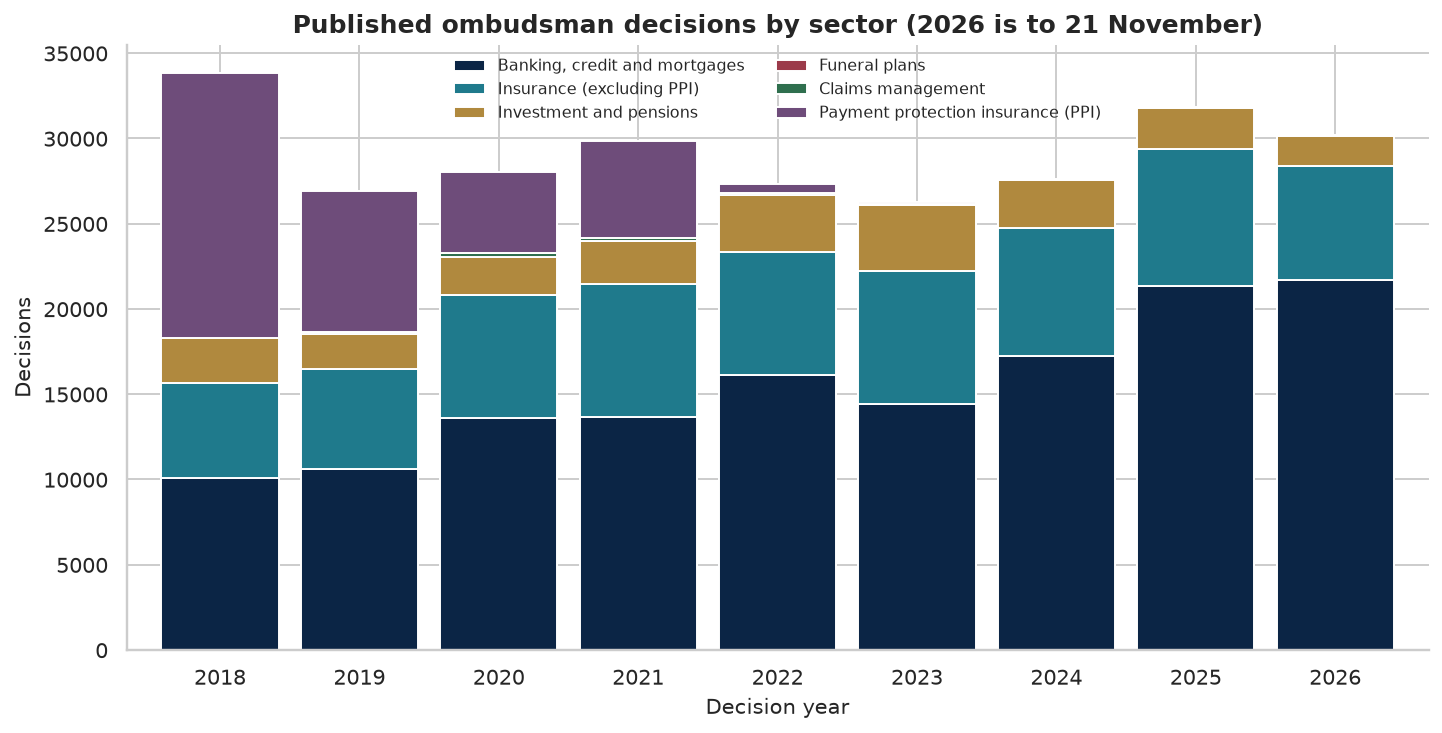

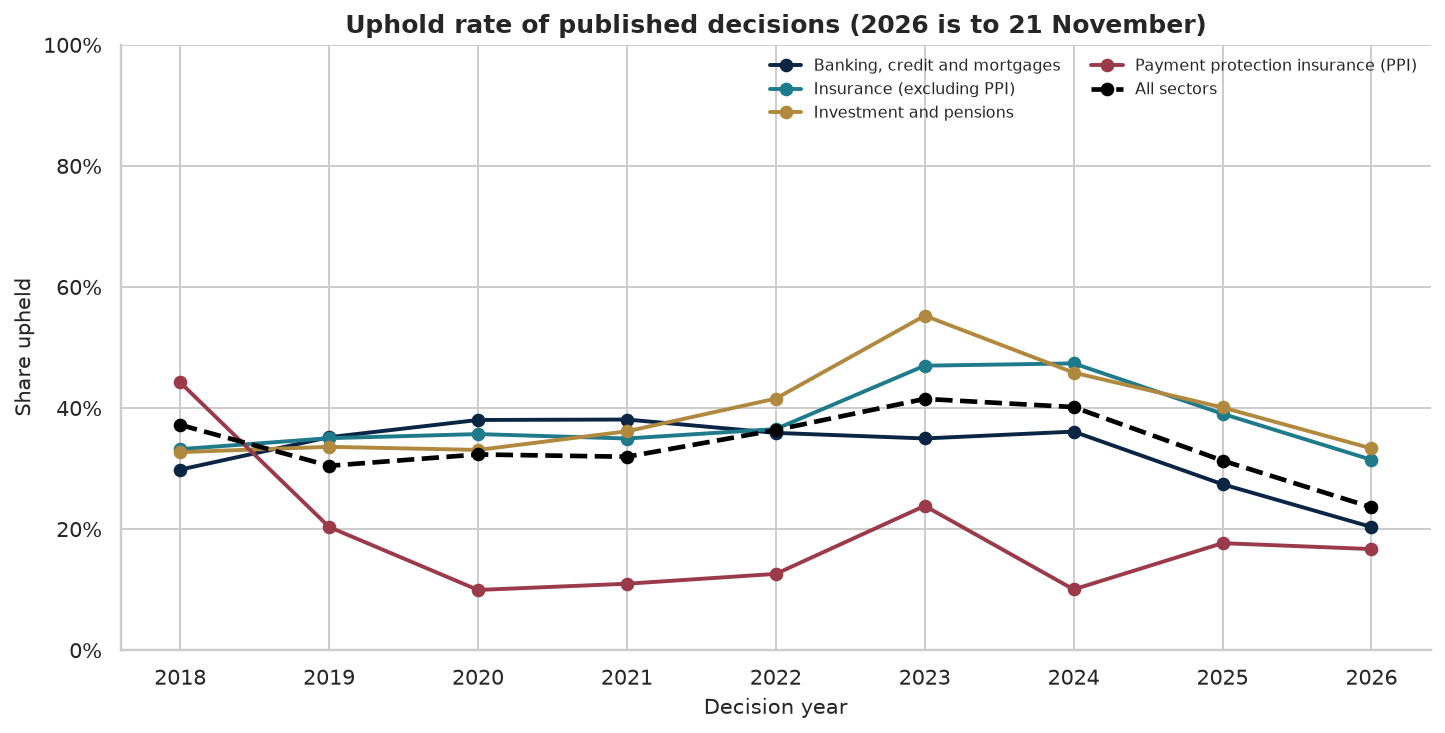

2018 Payment protection insurance (PPI): 15,511 decisions, uphold rate 44.2%
2024 Payment protection insurance (PPI): 20 decisions, uphold rate 10.0%
2018 Banking, credit and mortgages: 10,098 decisions, uphold rate 29.8%
2026 Banking, credit and mortgages: 21,686 decisions, uphold rate 20.3%


In [3]:
plot_sector_volumes(sectors)
plot_uphold_rates(sectors)
from IPython.display import Image, display
display(Image("reports/figures/sector_volumes.png"))
display(Image("reports/figures/uphold_rate_by_sector.png"))

detail = sectors[sectors.sector != "All sectors"].copy()
detail["uphold_rate"] = detail.upheld / detail.total.replace(0, pd.NA)
# Highlight the PPI wind-down and the latest banking year.
for year, sector in [(2018, "Payment protection insurance (PPI)"), (2024, "Payment protection insurance (PPI)"), (2018, "Banking, credit and mortgages"), (2026, "Banking, credit and mortgages")]:
    row = detail[(detail.year == year) & (detail.sector == sector)].iloc[0]
    print(f"{year} {sector}: {int(row.total):,} decisions, uphold rate {row.uphold_rate:.1%}")


## Topical issues

Keyword hit counts overlap. A motor-finance commission decision can also match "discretionary commission". They are a watchlist, not a partition of the register.

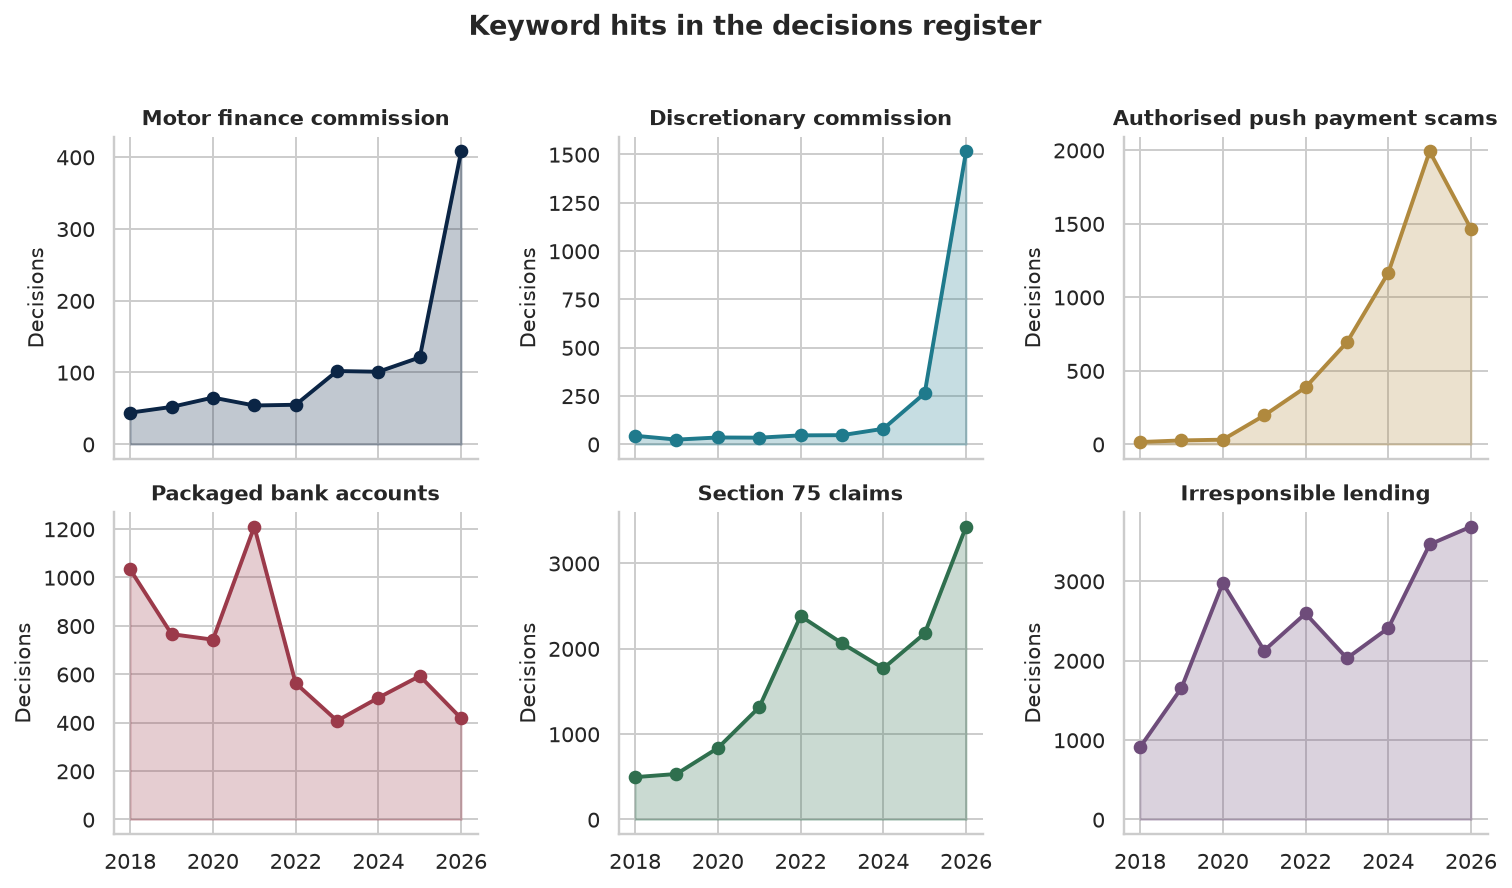

label  Authorised push payment scams  Discretionary commission  Irresponsible lending  Motor finance commission  Packaged bank accounts  Section 75 claims
year                                                                                                                                                      
2018                              15                        44                    910                        44                    1033                496
2019                              26                        24                   1655                        52                     766                533
2020                              31                        35                   2976                        65                     743                837
2021                             196                        34                   2127                        54                    1210               1315
2022                             387                        46        

In [4]:
plot_themes(themes)
display(Image("reports/figures/theme_volumes.png"))
pivot = themes.pivot(index="year", columns="label", values="total").fillna(0).astype(int)
print(pivot.to_string())


## The text sample

The modelling corpus is a stratified download of decisions from 2022 onwards, capped by sector and year, not a census. Uphold rates below are for that sample. Intervals are 95% Wilson intervals. Firm type is a name gazetteer, not a regulatory category.

Sample 3,099 decisions, 2022-05-17 to 2026-10-06
Uphold rate 37.0%. Median intake length 1242 characters.
Text source: {'pdf': 3099}
Products:
product
Banking and Payments      871
Insurance                 747
Consumer Credit           416
Pensions and Annuities    310
Investments               235
PPI                       176
Claims Management         140
Funeral plans             108
Mortgages                  96


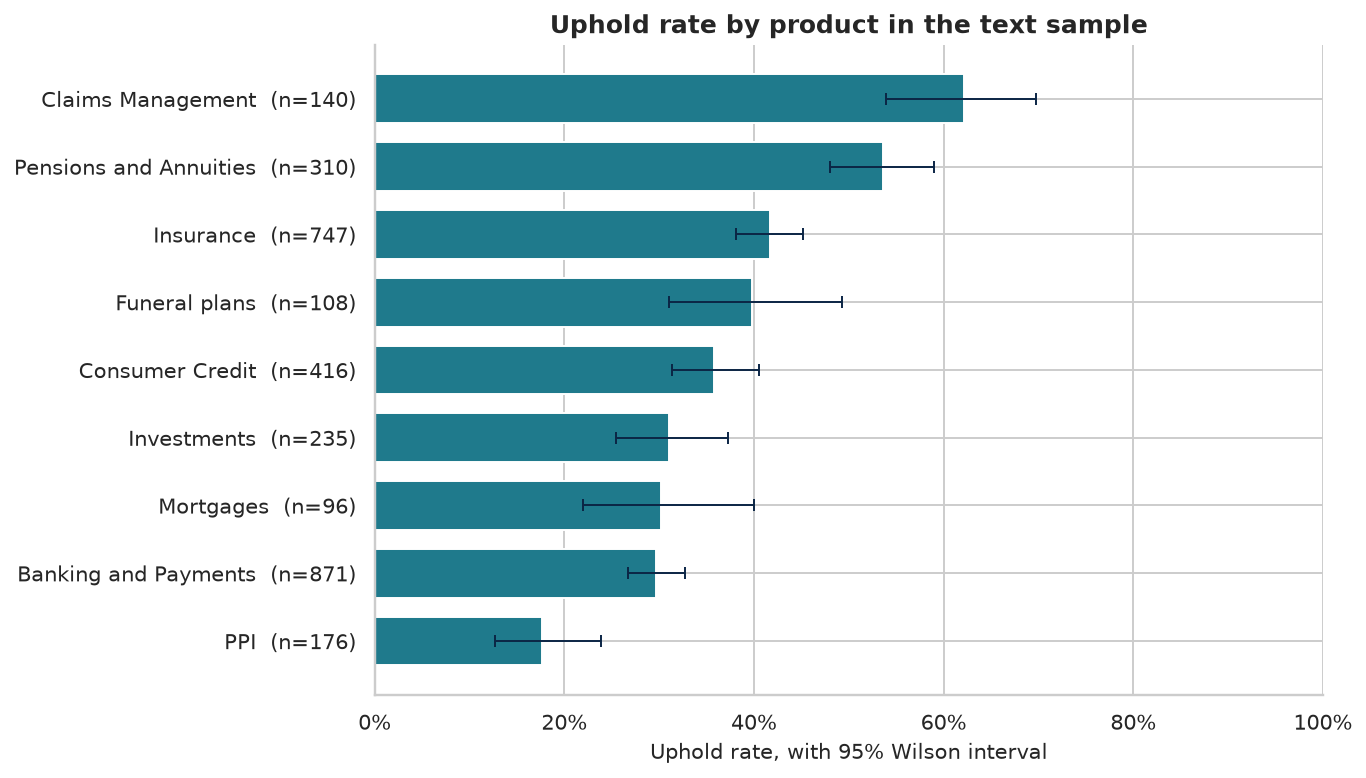

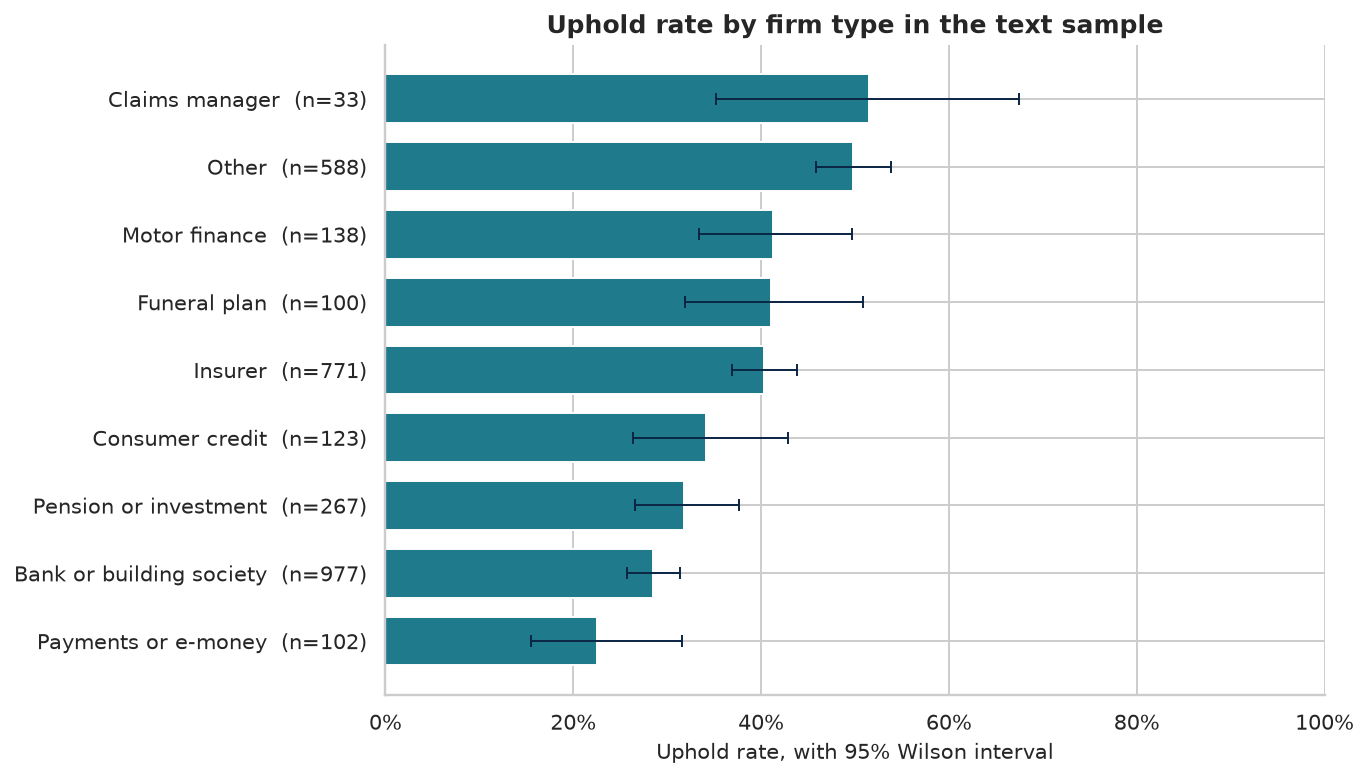

In [5]:
index_path = Path("data/aggregates/case_index.csv")
if not index_path.exists():
    print("Case index not built yet. Run python -m fos_triage.build_dataset")
else:
    cases = pd.read_csv(index_path, parse_dates=["date"])
    print(f"Sample {len(cases):,} decisions, {cases.date.min().date()} to {cases.date.max().date()}")
    print(f"Uphold rate {cases.upheld.mean():.1%}. Median intake length {cases.n_chars.median():.0f} characters.")
    print("Text source:", cases.text_source.value_counts().to_dict())
    print("Products:")
    print(cases["product"].value_counts().to_string())
    plot_rate_bars(cases, "product", "Uphold rate by product in the text sample", "reports/figures/uphold_by_product.png")
    plot_rate_bars(cases, "firm_type", "Uphold rate by firm type in the text sample", "reports/figures/uphold_by_firm_type.png", FIRM_TYPE_LABELS)
    display(Image("reports/figures/uphold_by_product.png"))
    display(Image("reports/figures/uphold_by_firm_type.png"))
